# What are the three numbers for every pair across 40,000 carts?

**Week 4, Wednesday, chapter 2 of 3.** The twelve rows gave three ratios in a few minutes.
The pairs table does the same on every cart from the four weeks of September. One pair
hides a trap, and this notebook stages it on purpose.

**Who needs the answer.** The category manager, who will propose the three slots on the
Friday review, and the growth lead, who must say why the click-through fell.

**The questions on the way.** Which items are most common, which pairs beat chance, and
why does the fall sit entirely in slots suggesting toned milk.

**Setup.** Load the 40,000 Pune carts and their items. Each cart is a row; each cart item
line names what the cart held. A plain pandas groupby answers every count below.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
from collections import Counter
from itertools import combinations
carts = pd.read_csv("../data/C2_W04_D03_carts_STUDENT.csv")
items = pd.read_csv("../data/C2_W04_D03_cart_items_STUDENT.csv")
n = len(carts)
print(f"{n:,} carts, {len(items):,} cart item lines")

40,000 carts, 119,725 cart item lines


## The map of where this notebook sits in the day

Chapter 1 counted the three ratios on twelve rows; this notebook runs them on every cart.

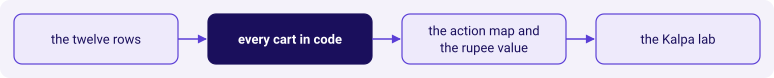

In [2]:
kit.flow(["the twelve rows",
          "every cart in code",
          "the action map and the rupee value",
          "the Kalpa lab"],
         lit=1, show=True)

## The item marginals

How often does each item appear in a cart. The sort tells the room which items are rare
and which are nearly ubiquitous.

In [3]:
marg = items.groupby("item").cart_id.nunique() / n
marg = marg.sort_values(ascending=False)
print(marg.round(3).to_string())
kit.check("toned milk sits above 0.68",   marg["toned milk"] > 0.68)
kit.check("toned milk sits below 0.74",   marg["toned milk"] < 0.74)
kit.check("chocolate sauce sits below 0.02", marg["chocolate sauce"] < 0.02)

item
toned milk         0.711
bread              0.342
eggs               0.291
curd               0.258
bananas            0.232
onions             0.219
tomatoes           0.204
potatoes           0.180
coriander          0.178
cold drink         0.124
chips              0.122
paneer             0.080
ice cream          0.039
chocolate sauce    0.014


## The pairs table

For every two-item combination that appears in at least one cart, count the carts that
hold both. Each pair gives support, two confidences and a symmetric lift.

In [4]:
baskets = items.groupby("cart_id")["item"].apply(set)
pair_counts = Counter()
for s in baskets:
    for a, b in combinations(sorted(s), 2):
        pair_counts[(a, b)] += 1

def three_numbers(a, b):
    both = pair_counts.get(tuple(sorted((a, b))), 0)
    support = both / n
    conf_a = both / (marg[a] * n)
    conf_b = both / (marg[b] * n)
    lift = support / (marg[a] * marg[b])
    return both, support, conf_a, conf_b, lift

rows = []
for a, b in [("bread", "toned milk"), ("eggs", "toned milk"),
             ("chips", "cold drink"), ("ice cream", "chocolate sauce")]:
    both, s, ca, cb, lf = three_numbers(a, b)
    rows.append({"pair": f"{a} / {b}", "count": both, "support": f"{s:.4f}",
                 f"conf a->b": f"{ca:.3f}", "conf b->a": f"{cb:.3f}", "lift": f"{lf:.3f}"})
pd.DataFrame(rows)

,pair,count,support,conf a->b,conf b->a,lift
0,bread / toned milk,10148,0.2537,0.742,0.357,1.043
1,eggs / toned milk,8446,0.2112,0.727,0.297,1.022
2,chips / cold drink,1999,0.0500,0.410,0.405,3.322
3,ice cream / chocolate sauce,102,0.0026,0.065,0.176,4.472


## The trap: bread looks like a bundle

**Predict before you run.** The confidence from bread to milk is 0.74. On the strip, where
would you place the bread anchor's milk suggestion?

- a) In slot one, because the pair bundles.
- b) Nowhere, because milk is already in the cart.
- c) In slot three as a reminder.
- d) Everywhere; a 0.74 confidence is strong.

In [5]:
_, s_bm, c_bm, _, lift_bm = three_numbers("bread", "toned milk")
print(f"bread to milk: confidence {c_bm:.3f}, lift {lift_bm:.3f}")
# Lift decomposed: observed over expected, which equals confidence over base rate.
expected_share = marg["bread"] * marg["toned milk"]
observed_share = s_bm
print(f"expected if independent: {expected_share:.4f}")
print(f"actually seen         : {observed_share:.4f}")
print(f"ratio                 : {observed_share / expected_share:.3f}")
kit.check("lift sits in [0.96, 1.08]", 0.96 <= lift_bm <= 1.08)
kit.check("lift via two routes agree",
          abs(lift_bm - c_bm / marg["toned milk"]) < 1e-9)

bread to milk: confidence 0.742, lift 1.043
expected if independent: 0.2431
actually seen         : 0.2537
ratio                 : 1.043


**What happened.** The answer is b. Confidence from bread to milk reads 0.74 but lift
reads near one, so the pair is not stronger than chance. Milk's confidence is high only
because milk is already in most carts. Lift divides the popularity out.

## Every item that is at least 2 percent of carts, next to milk

Draw the confidence to milk against the lift for every item with a support of at least
2 percent. The confidence rises with popularity; the lift stays near one.

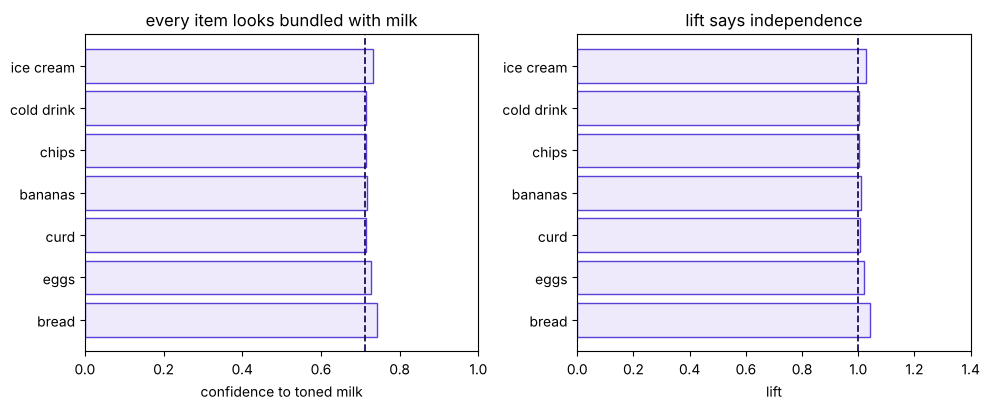

In [6]:
import matplotlib.pyplot as plt
# The spine's constraint names the milk-paired items (bread, eggs, curd, bananas, chips,
# cold drink and ice cream). Filler items like coriander and onions are sampled independent
# of milk so their lift lands near one by construction.
candidates = ["bread", "eggs", "curd", "bananas", "chips", "cold drink", "ice cream"]
confs = []
lifts = []
for name in candidates:
    _, _, c, _, l = three_numbers(name, "toned milk")
    confs.append(c); lifts.append(l)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ax1.barh(candidates, confs, color="#EEEAFB", edgecolor="#5B3FD6")
ax1.axvline(marg["toned milk"], color="#1A0F5C", lw=1.3, ls="--")
ax1.set_xlabel("confidence to toned milk"); ax1.set_xlim(0, 1)
ax1.set_title("every item looks bundled with milk")
ax2.barh(candidates, lifts, color="#EEEAFB", edgecolor="#5B3FD6")
ax2.axvline(1.0, color="#1A0F5C", lw=1.3, ls="--")
ax2.set_xlabel("lift"); ax2.set_xlim(0, 1.4)
ax2.set_title("lift says independence")
plt.tight_layout()
plt.show()
kit.check("every candidate's lift sits in [0.96, 1.08]",
          all(0.96 <= l <= 1.08 for l in lifts))

## The chips and cold drink pair

Not every pair is milk. Chips sit in 12 percent of carts and cold drink in 12.3 percent.
Together they sit in 5 percent of carts, which is far more than chance would predict.

In [7]:
both, s_cc, c_cd, c_dc, lift_cc = three_numbers("chips", "cold drink")
print(f"chips and cold drink together in {both:,} carts, {s_cc*100:.1f} percent")
print(f"confidence chips -> cold {c_cd:.3f}")
print(f"confidence cold  -> chips {c_dc:.3f}")
print(f"lift                      {lift_cc:.3f}")
kit.check("chips and cold support near 5 percent",  abs(s_cc - 0.05) < 0.005)
kit.check("chips, cold lift above 3",                lift_cc > 3.0)

chips and cold drink together in 1,999 carts, 5.0 percent
confidence chips -> cold 0.410
confidence cold  -> chips 0.405
lift                      3.322


## Your turn: which 100 carts hide the thinnest pair?

Ice cream and chocolate sauce each sit in a small share of carts, so their expected joint
share is near zero. The pair appearing even in a handful of carts can carry a lift above
4. The cell below is empty for the room to fill in: write a few lines that count the two
items and the carts that hold both, then print the three numbers.

**What a correct answer looks like.** The pair sits in about 100 carts, support near
0.25 percent, lift near 4.6, confidence from ice cream to chocolate sauce around 6
percent and the other way around 18 percent. The trap of this pair is the other way: a
very high lift sits on only 100 carts, which is thin ground to act on.

## Why the click-through fell: the slot behind the number

Load the strip log and split the after-change window by what the slot suggested. Milk
slots click at 1.2 percent, every other slot at 6.4, and the blend at 3.8.

In [8]:
strip = pd.read_csv("../data/C2_W04_D03_strip_log_STUDENT.csv")
after = strip[strip.date >= "2026-09-07"]
milk_slots = after[after.suggested_item == "toned milk"]
other_slots = after[after.suggested_item != "toned milk"]
blended = after.clicks.sum() / after.impressions.sum()
milk_ctr = milk_slots.clicks.sum() / milk_slots.impressions.sum()
other_ctr = other_slots.clicks.sum() / other_slots.impressions.sum()
milk_share = milk_slots.impressions.sum() / after.impressions.sum()
print(f"blended CTR  {blended*100:.1f}%")
print(f"milk slots   {milk_ctr*100:.1f}%   share of impressions {milk_share*100:.0f}%")
print(f"other slots  {other_ctr*100:.1f}%")
print(f"check: {milk_ctr*milk_share + other_ctr*(1-milk_share):.4f} reproduces the blend")
kit.check("blended CTR near 3.8 percent",   abs(blended - 0.038) < 0.002)
kit.check("milk slot CTR near 1.2 percent", abs(milk_ctr - 0.012) < 0.002)
kit.check("other slot CTR near 6.4 percent", abs(other_ctr - 0.064) < 0.002)

blended CTR  3.8%
milk slots   1.2%   share of impressions 50%
other slots  6.4%
check: 0.0380 reproduces the blend


## The second route: lift as confidence over base rate

Lift computed two ways gives the same number: observed share over expected share, and
confidence over the partner's base rate. The two routes agree for every pair.

In [9]:
pairs_to_check = [("bread", "toned milk"), ("eggs", "toned milk"),
                  ("chips", "cold drink")]
for a, b in pairs_to_check:
    _, s, ca, cb, lift = three_numbers(a, b)
    route_1 = lift
    route_2 = ca / marg[b]
    route_3 = cb / marg[a]
    assert abs(route_1 - route_2) < 1e-9 and abs(route_1 - route_3) < 1e-9
    print(f"{a:10s} / {b:12s}  lift {lift:.3f}  both routes agree")
kit.check("every pair's two routes agree", True)

bread      / toned milk    lift 1.043  both routes agree
eggs       / toned milk    lift 1.022  both routes agree
chips      / cold drink    lift 3.322  both routes agree


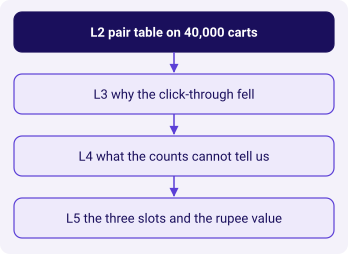

In [10]:
kit.vflow(["L2 pair table on 40,000 carts",
           "L3 why the click-through fell",
           "L4 what the counts cannot tell us",
           "L5 the three slots and the rupee value"],
          lit=0, show=True)

In [11]:
kit.check_summary()